# Text Classification with BERT and Cross-Validation

This notebook implements a text sequence classification model based on BERT with 5-fold cross-validation. The pipeline includes training the model, evaluating it, and saving/loading the best model.

## Import Libraries

In [24]:
import os
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.notebook import tqdm
from colorama import Fore, Style
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.metrics import (
    classification_report, 
    confusion_matrix,
    accuracy_score,
    roc_auc_score, 
    ConfusionMatrixDisplay
)
from transformers import BertForSequenceClassification, AutoTokenizer, get_scheduler
from torch.utils.data import DataLoader
from torch.optim import AdamW
from datasets import Dataset

## Data Preprocessing

In [25]:
# Loading the data
file_path = "all_channel_posts.csv"  # Provide the path to your CSV file
data = pd.read_csv(file_path)

# Extracting text and category labels
texts = data['text'].tolist()
labels = data['category'].tolist()

# Converting labels to numerical identifiers
# unique_labels = list(set(labels)).sort()
unique_labels = ['business', 'it', 'personal', 'other', 'weather', 'gaming', 'finances', 'stuff', 'political', 'advertisement', 'science', 'moscow']
label_to_id = {label: idx for idx, label in enumerate(unique_labels)}
id_to_label = {idx: label for label, idx in label_to_id.items()}
labels = [label_to_id[label] for label in labels]

# Splitting data into training and testing sets
train_texts, test_texts, train_labels, test_labels = train_test_split(
    texts, labels, test_size=0.1, random_state=42, stratify=labels
)

## Cross-Validation Setup

In [26]:
# Setting up cross-validation
kfold = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Loading the pre-trained tokenizer and setting up the device
model_name = "DeepPavlov/rubert-base-cased"
tokenizer = AutoTokenizer.from_pretrained(model_name)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## Tokenization Function

In [27]:
# Tokenization function
def tokenize_function(examples: dict) -> dict:
    """
    Tokenizes input texts using the pre-trained tokenizer.

    Args:
        examples (dict): A dictionary containing the texts to be tokenized.

    :returns: A dictionary containing tokenized texts.
    """
    return tokenizer(examples["text"], padding="max_length", truncation=True, max_length=128)

## Data Preparation for Training and Validation

In [28]:
# Preparing data for training and validation
def prepare_data(texts: list, labels: list, fold_idx: int, kfold: StratifiedKFold) -> tuple:
    """
    Prepares the training and validation datasets for the given fold iteration.

    :param texts: List of input texts.
    :param labels: List of labels.
    :param fold_idx: Index of the current fold.
    :param kfold: StratifiedKFold object for cross-validation.
    :returns: A tuple containing:
            - train_data: A Dataset object for the training data.
            - val_data: A Dataset object for the validation data.
    """
    train_idx, val_idx = list(kfold.split(texts, labels))[fold_idx]

    train_texts = [texts[i] for i in train_idx]
    train_labels = [labels[i] for i in train_idx]
    val_texts = [texts[i] for i in val_idx]
    val_labels = [labels[i] for i in val_idx]

    train_data = Dataset.from_dict({"text": train_texts, "label": train_labels})
    val_data = Dataset.from_dict({"text": val_texts, "label": val_labels})

    train_data = train_data.map(tokenize_function, batched=True)
    val_data = val_data.map(tokenize_function, batched=True)

    train_data.set_format(type="torch", columns=["input_ids", "attention_mask", "label"])
    val_data.set_format(type="torch", columns=["input_ids", "attention_mask", "label"])

    return train_data, val_data

## Model Training Function

In [29]:
# Model training function
def train_model(model: torch.nn.Module, train_loader: DataLoader, optimizer: torch.optim.Optimizer, scheduler: torch.optim.lr_scheduler.LambdaLR) -> float:
    """
    Trains the model for one epoch.

    :param model: The model to be trained.
    :param train_loader: DataLoader for the training set.
    :param optimizer: The optimizer for the model.
    :param scheduler: Learning rate scheduler.
    :returns: The average loss for the epoch.
    """
    model.train()
    total_loss = 0
    for batch in tqdm(train_loader, desc="Обучение"):
        input_ids = batch["input_ids"].to(device)
        attention_mask = batch["attention_mask"].to(device)
        labels = batch["label"].to(device)

        optimizer.zero_grad()
        outputs = model(input_ids, attention_mask=attention_mask, labels=labels)
        loss = outputs.loss
        total_loss += loss.item()

        loss.backward()
        optimizer.step()
        scheduler.step()

    avg_loss = total_loss / len(train_loader)
    return avg_loss

## Model Evaluation Function

In [30]:
# Model evaluation function
def evaluate_model(model: torch.nn.Module, val_loader: DataLoader, device: torch.device) -> tuple:
    """
    Evaluates the model on validation data.

    :param model: The model to be evaluated.
    :param val_loader: DataLoader for the validation set.
    :param device: The device (CPU or GPU) on which the model is run.
    :returns: Contains three elements:
            - all_preds: List of predicted labels.
            - all_labels: List of true labels.
            - all_probs: List of predicted probabilities for each class.
    """
    model.eval()
    all_preds = []
    all_labels = []
    all_probs = []
    with torch.no_grad():
        for batch in tqdm(val_loader, desc="Оценка"):
            input_ids = batch["input_ids"].to(device)
            attention_mask = batch["attention_mask"].to(device)
            labels = batch["label"].to(device)

            outputs = model(input_ids, attention_mask=attention_mask)
            probs = torch.softmax(outputs.logits, dim=1)
            preds = torch.argmax(outputs.logits, axis=1)

            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())
            all_probs.extend(probs.cpu().numpy())

    return all_preds, all_labels, all_probs

## Preparing Test Data

In [31]:
# Test data preparation function
def prepare_test_data(texts: list, labels: list) -> Dataset:
    """
    Prepares the test dataset for evaluation.

    :param texts: List of test texts.
    :param labels: List of test labels.
    :returns: The test dataset in a format suitable for DataLoader.
    """
    test_data = Dataset.from_dict({"text": texts, "label": labels})
    test_data = test_data.map(tokenize_function, batched=True)
    test_data.set_format(type="torch", columns=["input_ids", "attention_mask", "label"])
    return test_data

## Saving and Loading the Best Model

In [32]:
# Function to save the best model
def save_model(model_path: str, model: torch.nn.Module, tokenizer: AutoTokenizer) -> None:
    """
    Saves the model and tokenizer to disk.

    :param model_path: Path to the directory where the model and tokenizer will be saved.
    :param model: The trained model.
    :param tokenizer: The tokenizer used with the model.
    """
    model.save_pretrained(model_path)
    tokenizer.save_pretrained(model_path)
    print(f"{Fore.GREEN}Model saved at {Style.RESET_ALL}{model_path}")

In [33]:
# Function to load the best model
def load_model(model_path: str) -> tuple:
    """
    Loads the saved best model and tokenizer from the specified path.

    :param model_path: Path to the directory containing the saved model and tokenizer.
    :returns: The model and tokenizer, if available, otherwise None.
    """
    if not os.path.exists(model_path):
        raise FileNotFoundError(f"Model path {model_path} does not exist.")
    
    model = BertForSequenceClassification.from_pretrained(model_path)
    tokenizer = AutoTokenizer.from_pretrained(model_path)
    print(f"{Fore.GREEN}Model and tokenizer loaded from {Style.RESET_ALL}{model_path}")
    return model, tokenizer

## Main Training Loop

In [34]:
# Training parameters
epochs = 3
batch_size = 8
learning_rate = 5e-5

## Final Evaluation

In [35]:
# Loading the best model after training
model, tokenizer = load_model("model")
model.to(device)

# Preparing the test dataset for final evaluation
test_data = prepare_test_data(test_texts, test_labels)
test_loader = DataLoader(test_data, batch_size=batch_size)

# Final evaluation on the test set
all_preds, all_labels, all_probs = evaluate_model(model, test_loader, device)

Model and tokenizer loaded from model


Map:   0%|          | 0/2210 [00:00<?, ? examples/s]

Оценка:   0%|          | 0/277 [00:00<?, ?it/s]

## Results and Metrics

In [40]:
# Printing final evaluation results
accuracy = accuracy_score(all_labels, all_preds)
print(f"{Fore.MAGENTA}Test Accuracy: {Style.RESET_ALL}{accuracy:.4f}\n")

# Unique classes present in the test set
present_classes = sorted(set(all_labels))

filtered_classes = [cls for cls in present_classes if cls != 3]

# Printing classification report
print(f"{Fore.MAGENTA}Classification Report:{Style.RESET_ALL}")
print(classification_report(
    all_labels,
    all_preds,
    labels=filtered_classes,
    target_names=[id_to_label[idx] for idx in filtered_classes]
))

if len(set(all_labels)) == len(set(all_preds)):
    all_labels_ovr = np.zeros((len(all_labels), len(unique_labels)))
    for i, label in enumerate(all_labels):
        all_labels_ovr[i][label] = 1

    all_probs = np.array(all_probs)
    roc_auc = roc_auc_score(all_labels_ovr, all_probs, average="macro", multi_class="ovr")
    print(f"{Fore.MAGENTA}Macro-Averaged ROC-AUC: {Style.RESET_ALL}{roc_auc:.4f}")

Test Accuracy: 0.9443

Classification Report:
               precision    recall  f1-score   support

     business       0.92      0.91      0.92       203
           it       0.94      0.98      0.96       241
     personal       0.95      0.95      0.95       339
      weather       0.93      0.95      0.94        40
       gaming       0.96      0.94      0.95        52
     finances       0.90      0.94      0.92       114
        stuff       0.90      0.93      0.92        61
    political       0.98      0.99      0.99       463
advertisement       0.89      0.91      0.90        44
      science       1.00      0.98      0.99       128
       moscow       0.96      0.94      0.95       192

    micro avg       0.95      0.96      0.95      1877
    macro avg       0.94      0.95      0.94      1877
 weighted avg       0.95      0.96      0.95      1877

Macro-Averaged ROC-AUC: 0.9969


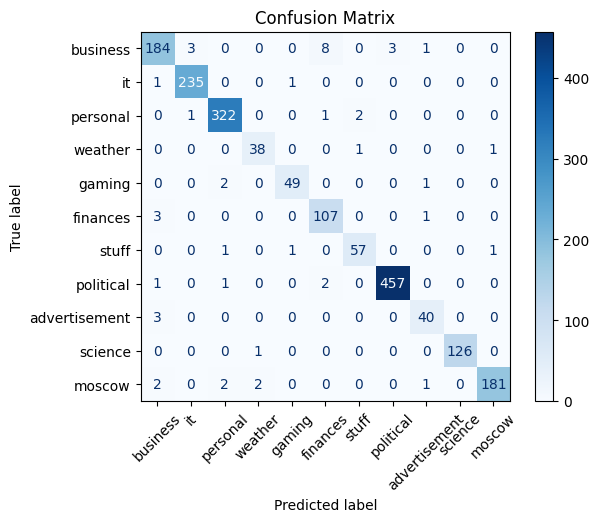

In [41]:
# Исключаем класс с индексом 3
present_classes = sorted(set(all_labels).union(set(all_preds)))
filtered_classes = [cls for cls in present_classes if cls != 3]

# Строим матрицу ошибок только для оставшихся классов
cm = confusion_matrix(all_labels, all_preds, labels=filtered_classes)

# Визуализируем, передавая только соответствующие названия классов
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=[id_to_label[idx] for idx in filtered_classes])

disp.plot(cmap="Blues", xticks_rotation=45)
plt.title("Confusion Matrix")
plt.show()